# Summative Lab – Analytics Firm Clients: Customer Reviews Analysis

This notebook is a **starter notebook** for the three parts of the lab:

1. NLP  
2. Time Series  
3. Neural Networks  

Use the comments and TODO prompts to guide your work. The notebook is intentionally incomplete so you can implement the analysis yourself.


## Part 1: NLP

In this section, you will clean and preprocess review text, explore frequent words and bigrams, and visualize key language patterns in the dataset.


In [1]:
# =========================
# Part 1: NLP Starter Code
# =========================

# TODO: Import the libraries you need for:
# - data handling
# - plotting
# - text preprocessing
# - tokenization / stopwords / lemmatization
# - counting words and bigrams

# Example:
# import pandas as pd

# TODO: Download any required NLTK resources.

# TODO: Load the dataset.
# Hint: The file used in this lab is 'amazon_reviews_lab.csv'
# df = ...

# TODO: Explore the dataset.
# Suggested checks:
# - shape
# - value counts for the rating column
# - preview the first few rows

# TODO: Create preprocessing tools such as:
# - stop_words
# - lemmatizer

# TODO: Write a function called preprocess_text(text) that:
# 1. converts text to lowercase
# 2. removes URLs
# 3. removes punctuation
# 4. tokenizes the text
# 5. keeps alphabetic tokens only
# 6. removes stopwords
# 7. lemmatizes the remaining tokens
# 8. returns the cleaned tokens

# def preprocess_text(text):
#     pass

# TODO: Apply your preprocessing function to the review text column
# and store the output in a new column such as 'processed_tokens'.

# TODO: Combine all tokens into one list so you can compute word frequencies.

# TODO: Use Counter to identify the most common words.

# TODO: Generate bigrams from the token list and identify the most common bigrams.

# TODO: Create at least one visualization of the most common words.
# You may also choose to visualize the most common bigrams.

# Reflection prompt:
# What do the most common words or phrases suggest about customer sentiment or product experience?


In [2]:
#importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
import string

from collections import Counter
import nltk

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.util import ngrams

# Download resources needed for text preprocessing
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [3]:
#Loading the dataset
df=pd.read_csv("/content/amazon_reviews_lab.csv")

In [4]:
#Exploring the dataset
df.head()

,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


In [5]:
df.tail()

,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
992,0972683275,5,"This is a great buy, compared to a $60 or more...",Excelant mount for Tv. Would buy more if I nee...,"07 12, 2014",1.405123e+09,2014-07-12,positive,14
993,9575871979,5,"I use CR123A batteries like candy, I didn't kn...",Great value and saves a ton after two uses.,"07 13, 2014",1.405210e+09,2014-07-13,positive,60
994,1400699169,5,A year after Barnes and Noble dropped the pric...,Great Value! Don't wait too long... they are n...,"07 14, 2014",1.405296e+09,2014-07-14,positive,465
995,1400532655,1,Not worth saving a few bucks. Go with an iPad.,Not user friendly. Very time consuming to find...,"07 14, 2014",1.405296e+09,2014-07-14,negative,10
996,1400698987,5,"perfect, as described Thank you",Five Stars,"07 17, 2014",1.405555e+09,2014-07-17,positive,5


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 997 entries, 0 to 996
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           997 non-null    object 
 1   rating               997 non-null    int64  
 2   review_text          997 non-null    object 
 3   review_summary       997 non-null    object 
 4   review_time_raw      997 non-null    object 
 5   unix_review_time     997 non-null    float64
 6   timestamp            997 non-null    object 
 7   sentiment_label      997 non-null    object 
 8   review_length_words  997 non-null    int64  
dtypes: float64(1), int64(2), object(6)
memory usage: 70.2+ KB


In [7]:
df.columns.tolist()

['product_id',
 'rating',
 'review_text',
 'review_summary',
 'review_time_raw',
 'unix_review_time',
 'timestamp',
 'sentiment_label',
 'review_length_words']

In [8]:
df.isnull().sum()

,0
product_id,0
rating,0
review_text,0
review_summary,0
review_time_raw,0
unix_review_time,0
timestamp,0
sentiment_label,0
review_length_words,0


In [9]:
df['rating'].value_counts().sort_index()

,count
rating,
1,87
2,48
3,94
4,188
5,580


In [10]:
df['sentiment_label'].value_counts()

,count
sentiment_label,
positive,768
negative,135
neutral,94


In [11]:
text_col = 'review_text'

print(df[text_col].head())

0    This film is definitely not for anyone who is ...
1    This movie was playing at Radio City Music Hal...
2    I would love to buy this movie as I have been ...
3    The advertisment for this DVD on Amazon was in...
4    I bought some of these to try with a light usi...
Name: review_text, dtype: object


**Creating preprocessing tools**

In [12]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

len(stop_words)

198

**Function preprocess_text function that:**

In [13]:
def preprocess_text(text):
    #Handle missing or non-string values
    if pd.isna(text):
        return []

    #Converting text to lowercase
    text = str(text).lower()

    #Removing URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    #Removing punctuation and other non-letter characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    #Tokenize the text
    tokens = word_tokenize(text)

    #Keep alphabetic tokens only
    tokens = [word for word in tokens if word.isalpha()]

    #Removing stopwords
    tokens = [word for word in tokens if word not in stop_words]

    #Lemmatize the remaining words
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    #Return the cleaned tokens
    return tokens


**Testing the preprocessing function**

In [14]:
sample_text = "The cable works as advertised and the price is unbeatable. I am not using it for a camcorder but for a canon elph camera with HDMI out. The photos and videos look great"

print("Original text:")
print(sample_text)

print("\nProcessed tokens:")
print(preprocess_text(sample_text))


Original text:
The cable works as advertised and the price is unbeatable. I am not using it for a camcorder but for a canon elph camera with HDMI out. The photos and videos look great

Processed tokens:
['cable', 'work', 'advertised', 'price', 'unbeatable', 'using', 'camcorder', 'canon', 'elph', 'camera', 'hdmi', 'photo', 'video', 'look', 'great']


**Testing the preprocessing function**

In [15]:
sample_text = "The cable works as advertised and the price is unbeatable. I am not using it for a camcorder but for a canon elph camera with HDMI out. The photos and videos look great"
print("Original text:")
print(sample_text)

print("\nProcessed tokens:")
print(preprocess_text(sample_text))

Original text:
The cable works as advertised and the price is unbeatable. I am not using it for a camcorder but for a canon elph camera with HDMI out. The photos and videos look great

Processed tokens:
['cable', 'work', 'advertised', 'price', 'unbeatable', 'using', 'camcorder', 'canon', 'elph', 'camera', 'hdmi', 'photo', 'video', 'look', 'great']


**Applying the preprocessing function to all review text column**

In [16]:
df['processed_tokens'] = df[text_col].apply(preprocess_text)

#Show the original reviews and their processed tokens
df[[text_col, 'processed_tokens']].head(10)


,review_text,processed_tokens
0,This film is definitely not for anyone who is ...,"[film, definitely, anyone, especially, fond, i..."
1,This movie was playing at Radio City Music Hal...,"[movie, playing, radio, city, music, hall, bac..."
2,I would love to buy this movie as I have been ...,"[would, love, buy, movie, hannibal, missouri, ..."
3,The advertisment for this DVD on Amazon was in...,"[advertisment, dvd, amazon, incorrect, ad, sta..."
4,I bought some of these to try with a light usi...,"[bought, try, light, using, work, advertised, ..."
5,"For the money you can't go wrong. Yes, it has ...","[money, go, wrong, yes, litlle, play, mechanis..."
6,I hadn't heard of this 1973 movie version of t...,"[heard, movie, version, classic, mark, twain, ..."
7,I've had this kit for a few months now and hav...,"[kit, month, recharged, pair, battery, time, t..."
8,"Very fast, dependable OS (way better than the ...","[fast, dependable, o, way, better, wm, good, b..."
9,The Dell Axim X30 624 Mhz was released in 2004...,"[dell, axim, x, mhz, released, still, lot, goi..."


**Calculating the total number of all tokens from reviews**

In [17]:
all_tokens = [token
    for document in df['processed_tokens']
    for token in document]

print("Total number of tokens:", len(all_tokens))
print("First 10 tokens:", all_tokens[:10])

Total number of tokens: 72807
First 10 tokens: ['film', 'definitely', 'anyone', 'especially', 'fond', 'independent', 'delightfully', 'manipulative', 'clever', 'boy']


**Identifying the most common words**

In [18]:
word_counts = Counter(all_tokens)

print("Top 15 most common words")

for word, count in word_counts.most_common(15):
    print(word, count)

Top 15 most common words
nook 1580
book 986
one 596
kindle 592
screen 536
like 474
read 464
work 463
great 444
tablet 444
use 432
tv 427
get 426
device 399
would 383


**Generating bigrams**

In [19]:
#Generating bigrams from token list and checking the most common bigrams
all_bigrams = []

for document in df['processed_tokens']:
    document_bigrams = list(ngrams(document, 2))
    all_bigrams.extend(document_bigrams)

bigram_counts = Counter(all_bigrams)

print("Top 15 most common bigrams")

for bigram, count in bigram_counts.most_common(15):
    print(' '.join(bigram), count)

Top 15 most common bigrams
b n 330
barnes noble 166
nook color 135
e reader 132
battery life 98
touch screen 96
sd card 90
nook hd 80
work great 65
nook tablet 64
kindle fire 61
work well 59
read book 55
wall mount 53
wi fi 48


**Visualization**

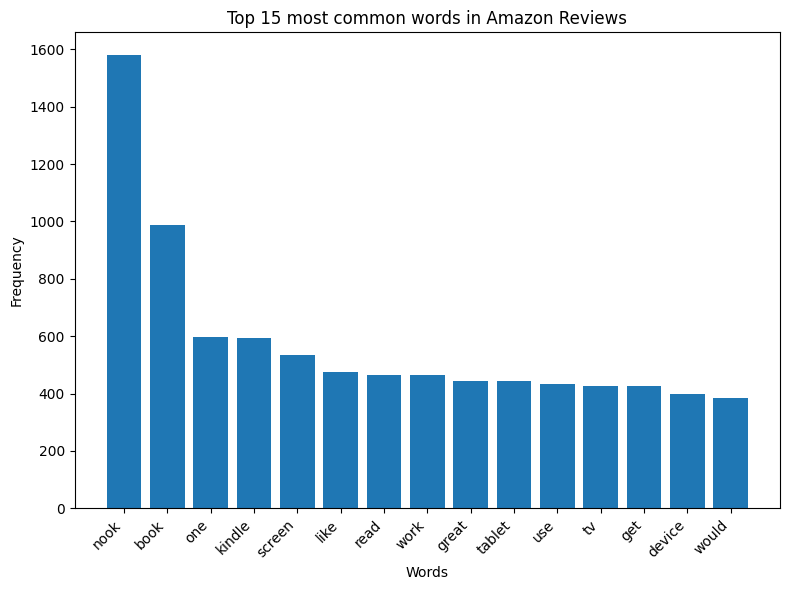

In [20]:
#Visualizing the top 15 most common words
top_words = word_counts.most_common(15)

words = [word for word, count in top_words]
frequencies = [count for word, count in top_words]

plt.figure(figsize=(8, 6))

plt.bar(words, frequencies)

plt.title('Top 15 most common words in Amazon Reviews')
plt.xlabel('Words')
plt.ylabel('Frequency')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

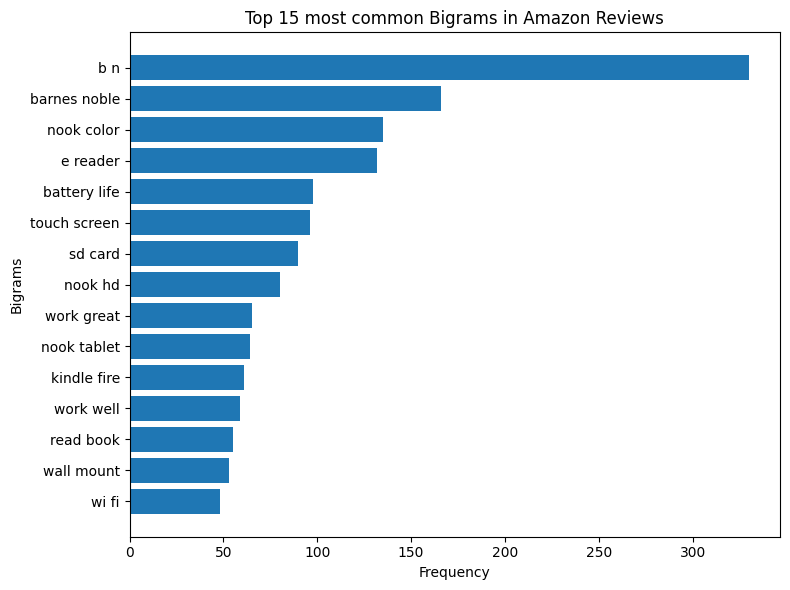

In [21]:
#Visualizing the top 15 most common bigrams
top_bigrams = bigram_counts.most_common(15)

phrases = [' '.join(bigram) for bigram, count in top_bigrams]
bigram_frequencies = [count for bigram, count in top_bigrams]

plt.figure(figsize=(8, 6))

plt.barh(phrases[::-1], bigram_frequencies[::-1])

plt.title('Top 15 most common Bigrams in Amazon Reviews')
plt.xlabel('Frequency')
plt.ylabel('Bigrams')
plt.tight_layout()
plt.show()

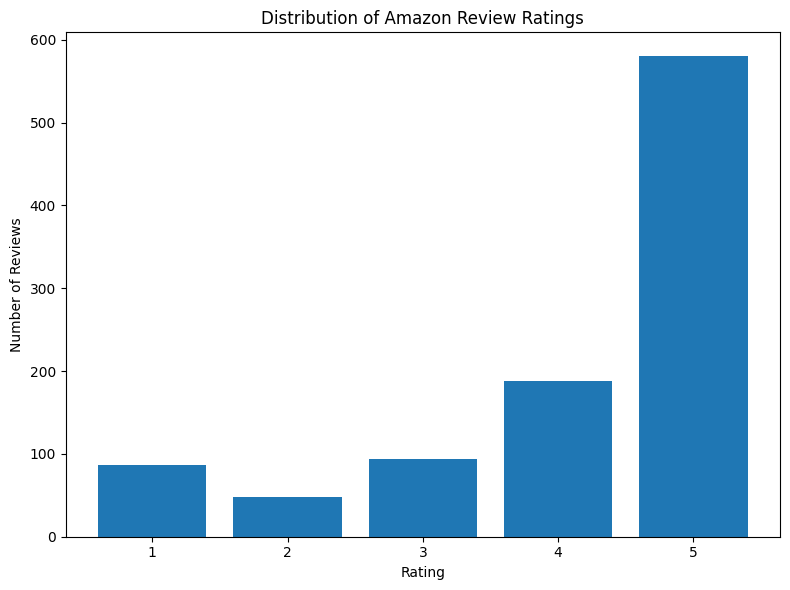

In [22]:
#Visualizing rating distribution
rating_counts = df['rating'].value_counts().sort_index()

plt.figure(figsize=(8, 6))

plt.bar(rating_counts.index.astype(str), rating_counts.values)

plt.title('Distribution of Amazon Review Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')
plt.tight_layout()
plt.show()

###What do the most common words or phrases suggest about customer sentiment or product experience?

The most common words shows that customers mainly discuss nook and kindle devices, reading, screens, and product functionality. The word nook appeared 1,580 times, making it the most frequent word. Other common words, such as screen,book,read, and work, show that customers frequently discuss device features and their experiences using the products

The bigram analysis showed phrases such as battery life,touch screen,sd card,work great, and work well. These phrases suggest that customers are interested in device performance, hardware features, and functionality.Two-letter words such as work great and work well may show positive experiences, while terms such as battery life identifies what products customers normally discuss

The rating distribution showed that 580 reviews had five stars, while 188 had four stars.Also, 768 reviews were positive, 135 negative, and 94 neutral. This shows that customer sentiment was generally positive, although some customers may have experienced problems or had mixed experiences

In conclusion,word frequency and bigram analysis helped identify common topics in customer feedback, while the rating and sentiment distributions provided customer opinions. These findings can help a company understand customer experiences and identify product features that may require further investigation

## Part 2: Time Series

In this section, you will analyze review activity over time by converting timestamps, resampling the data, and visualizing trends in review volume and ratings.


In [23]:
# ==============================
# Part 2: Time Series Starter Code
# ==============================

# TODO: Import the libraries you need.

# TODO: Load the same review dataset.
# df = ...

# TODO: Convert the timestamp column to datetime format.

# TODO: Inspect the date range in the dataset.
# Suggested checks:
# - earliest timestamp
# - latest timestamp

# TODO: Resample the data by month to calculate:
# 1. monthly review count
# 2. monthly average rating

# Suggested variable names:
# monthly_review_count = ...
# monthly_avg_rating = ...

# TODO: Plot monthly review volume over time.

# TODO: Plot average monthly rating over time.

# TODO: Compute a rolling average for the monthly average rating.
# A 3-month rolling average is a good starting point.

# TODO: Plot both:
# - the original monthly average rating
# - the rolling average
# on the same figure.

# Reflection prompt:
# What overall trends do you notice in review activity and customer ratings over time?


In [24]:
#importing the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

import warnings
warnings.filterwarnings('ignore')

In [25]:
df=pd.read_csv("/content/amazon_reviews_lab.csv")

**Exploring the dataset**

In [26]:
df.shape

(997, 9)

In [27]:
df.columns.tolist()

['product_id',
 'rating',
 'review_text',
 'review_summary',
 'review_time_raw',
 'unix_review_time',
 'timestamp',
 'sentiment_label',
 'review_length_words']

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 997 entries, 0 to 996
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           997 non-null    object 
 1   rating               997 non-null    int64  
 2   review_text          997 non-null    object 
 3   review_summary       997 non-null    object 
 4   review_time_raw      997 non-null    object 
 5   unix_review_time     997 non-null    float64
 6   timestamp            997 non-null    object 
 7   sentiment_label      997 non-null    object 
 8   review_length_words  997 non-null    int64  
dtypes: float64(1), int64(2), object(6)
memory usage: 70.2+ KB


In [29]:
df.isnull().sum()

,0
product_id,0
rating,0
review_text,0
review_summary,0
review_time_raw,0
unix_review_time,0
timestamp,0
sentiment_label,0
review_length_words,0


**Converting timestamp column to datetime format**

In [30]:
df['timestamp'] = pd.to_datetime(df['timestamp'],errors='coerce',utc=True)

# Remove timezone information for simpler date-based analysis
df['timestamp'] = df['timestamp'].dt.tz_convert(None)

print(df[['timestamp', 'rating']].head())

print("\nTimestamp data type:")
print(df['timestamp'].dtype)

   timestamp  rating
0 2000-05-12       2
1 2002-08-26       5
2 2005-08-06       1
3 2005-09-11       1
4 2007-10-15       5

Timestamp data type:
datetime64[ns]


**Checking the range date**

In [31]:
#earliest and latest timestamp
print("Earliest review date -", df['timestamp'].min())
print("Latest review date -", df['timestamp'].max())

print("\nNumber of missing timestamps -", df['timestamp'].isnull().sum())

Earliest review date - 2000-05-12 00:00:00
Latest review date - 2014-07-17 00:00:00

Number of missing timestamps - 0


**Preparing the data for time series anlysis**

In [32]:
df_ts = df.dropna(subset=['timestamp']).copy()

# Sorting the reviews
df_ts = df_ts.sort_values('timestamp')

print("Rows that are there for time series analysis:", len(df_ts))

print("\nFirst five dates - ")
print(df_ts['timestamp'].head())

print("\nLast five dates - ")
print(df_ts['timestamp'].tail())

Rows that are there for time series analysis: 997

First five dates - 
0   2000-05-12
1   2002-08-26
2   2005-08-06
3   2005-09-11
4   2007-10-15
Name: timestamp, dtype: datetime64[ns]

Last five dates - 
992   2014-07-12
993   2014-07-13
995   2014-07-14
994   2014-07-14
996   2014-07-17
Name: timestamp, dtype: datetime64[ns]


**Resample the data by month to calculate;**

In [33]:
#monthly review count
monthly_review_count = (df_ts.set_index('timestamp')
         .resample('MS')
         .size())

print(monthly_review_count.head(12))

timestamp
2000-05-01    1
2000-06-01    0
2000-07-01    0
2000-08-01    0
2000-09-01    0
2000-10-01    0
2000-11-01    0
2000-12-01    0
2001-01-01    0
2001-02-01    0
2001-03-01    0
2001-04-01    0
Freq: MS, dtype: int64


In [34]:
#monthly review rating
monthly_avg_rating = (df_ts.set_index('timestamp')['rating']
         .resample('MS')
         .mean())

print(monthly_avg_rating.head(12))

timestamp
2000-05-01    2.0
2000-06-01    NaN
2000-07-01    NaN
2000-08-01    NaN
2000-09-01    NaN
2000-10-01    NaN
2000-11-01    NaN
2000-12-01    NaN
2001-01-01    NaN
2001-02-01    NaN
2001-03-01    NaN
2001-04-01    NaN
Freq: MS, Name: rating, dtype: float64


**Visualization**

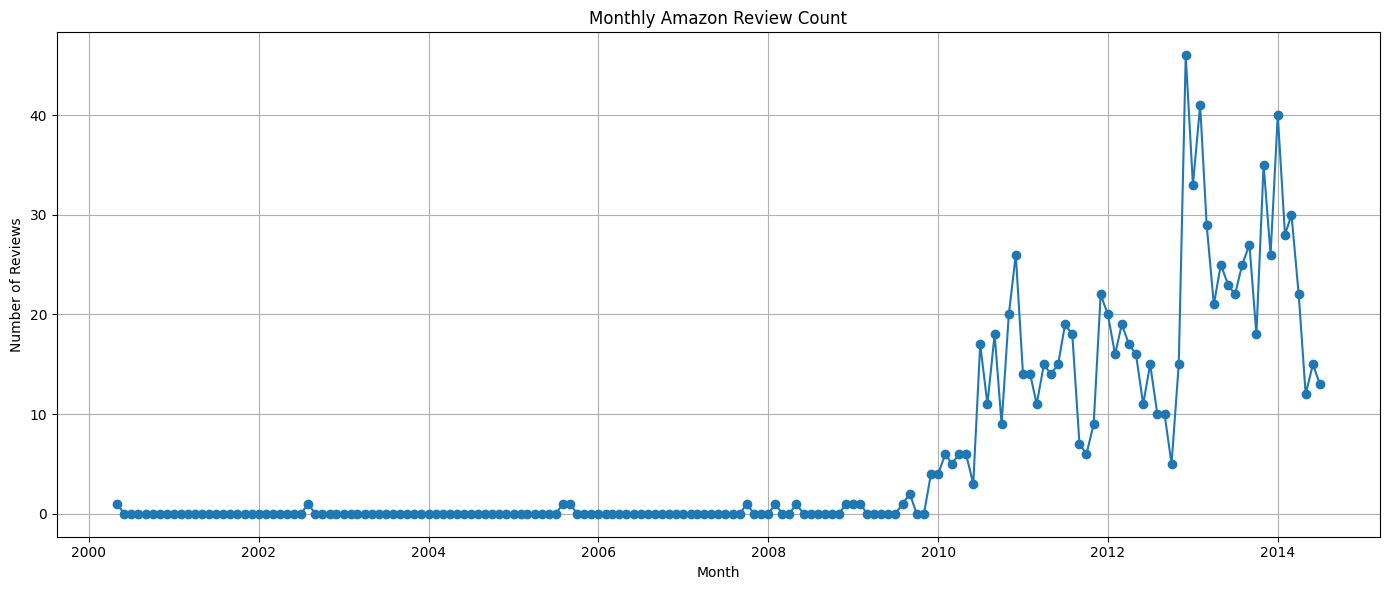

In [35]:
#Plotting monthly review count over time
plt.figure(figsize=(14,6))
plt.plot(monthly_review_count.index,
    monthly_review_count.values,
    marker='o')

plt.title('Monthly Amazon Review Count')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.grid(True)
plt.tight_layout()
plt.show()

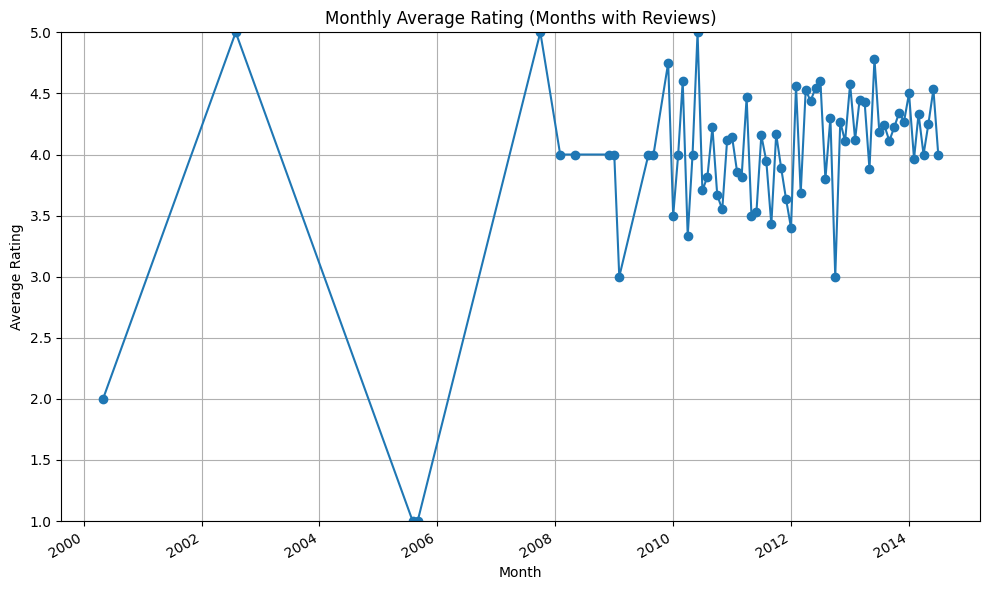

In [36]:
#Plotting monthly review count over time with only the months that have the reviews
monthly_avg_rating.dropna().plot(figsize=(10,6),marker='o')

plt.title('Monthly Average Rating (Months with Reviews)')
plt.xlabel('Month')
plt.ylabel('Average Rating')
plt.ylim(1, 5)
plt.grid(True)
plt.tight_layout()
plt.show()

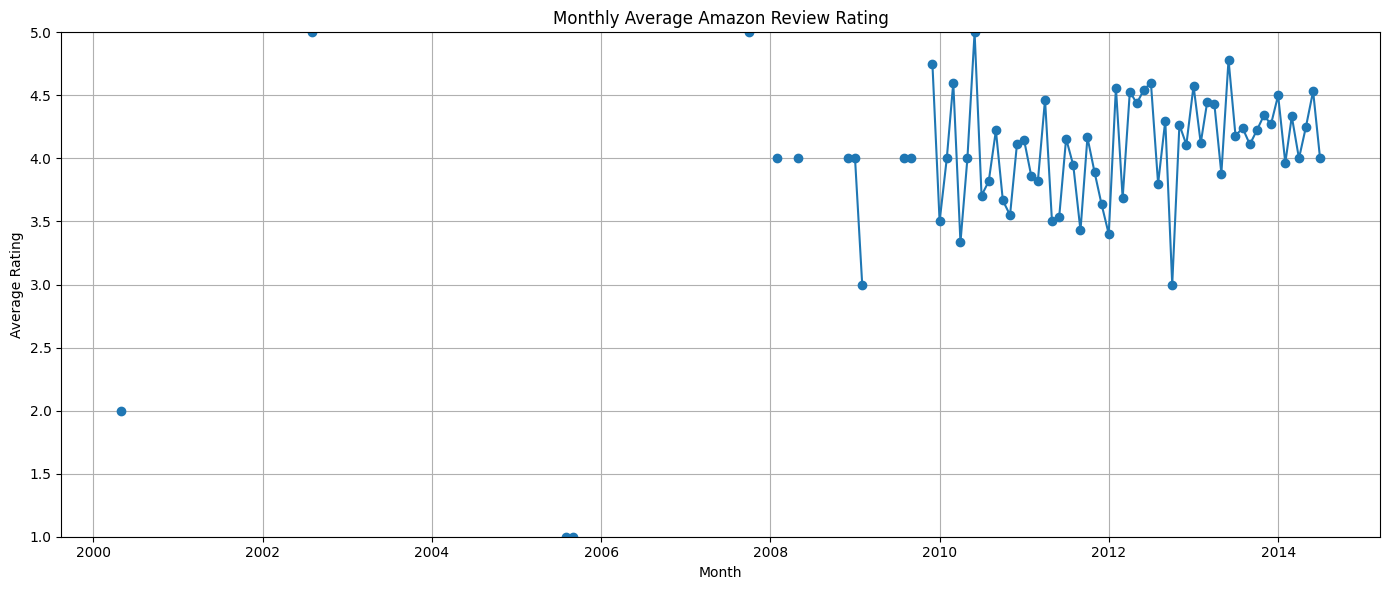

In [37]:
#Plotting monthly average ratings over time
plt.figure(figsize=(14, 6))
plt.plot(monthly_avg_rating.index,
    monthly_avg_rating.values,
    marker='o')

plt.title('Monthly Average Amazon Review Rating')
plt.xlabel('Month')
plt.ylabel('Average Rating')
plt.ylim(1, 5)
plt.grid(True)
plt.tight_layout()
plt.show()

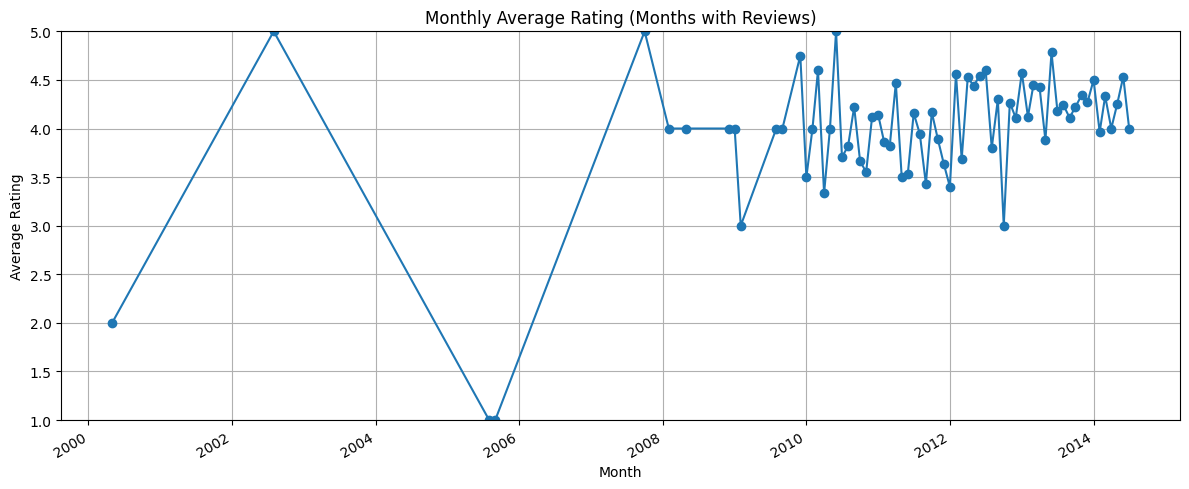

In [38]:
#plotting monthly average rating over time with only the months that have ratings
monthly_avg_rating.dropna().plot(figsize=(12, 5),marker='o')

plt.title('Monthly Average Rating (Months with Reviews)')
plt.xlabel('Month')
plt.ylabel('Average Rating')
plt.ylim(1, 5)
plt.grid(True)
plt.tight_layout()
plt.show()

**Compute a rolling average for the monthly average rating**

In [39]:
#Calculating a 3-month rolling average
rolling_avg_rating = monthly_avg_rating.rolling(window=3,min_periods=3).mean()

print("Monthly ratings and rolling averages - ")

rating_comparison = pd.DataFrame({
    'monthly_avg_rating': monthly_avg_rating,
    'rolling_avg_rating': rolling_avg_rating})

print(rating_comparison.head(12))

Monthly ratings and rolling averages - 
            monthly_avg_rating  rolling_avg_rating
timestamp                                         
2000-05-01                 2.0                 NaN
2000-06-01                 NaN                 NaN
2000-07-01                 NaN                 NaN
2000-08-01                 NaN                 NaN
2000-09-01                 NaN                 NaN
2000-10-01                 NaN                 NaN
2000-11-01                 NaN                 NaN
2000-12-01                 NaN                 NaN
2001-01-01                 NaN                 NaN
2001-02-01                 NaN                 NaN
2001-03-01                 NaN                 NaN
2001-04-01                 NaN                 NaN


**Plotting both the original monthly average rating and rolling average on the same figure**

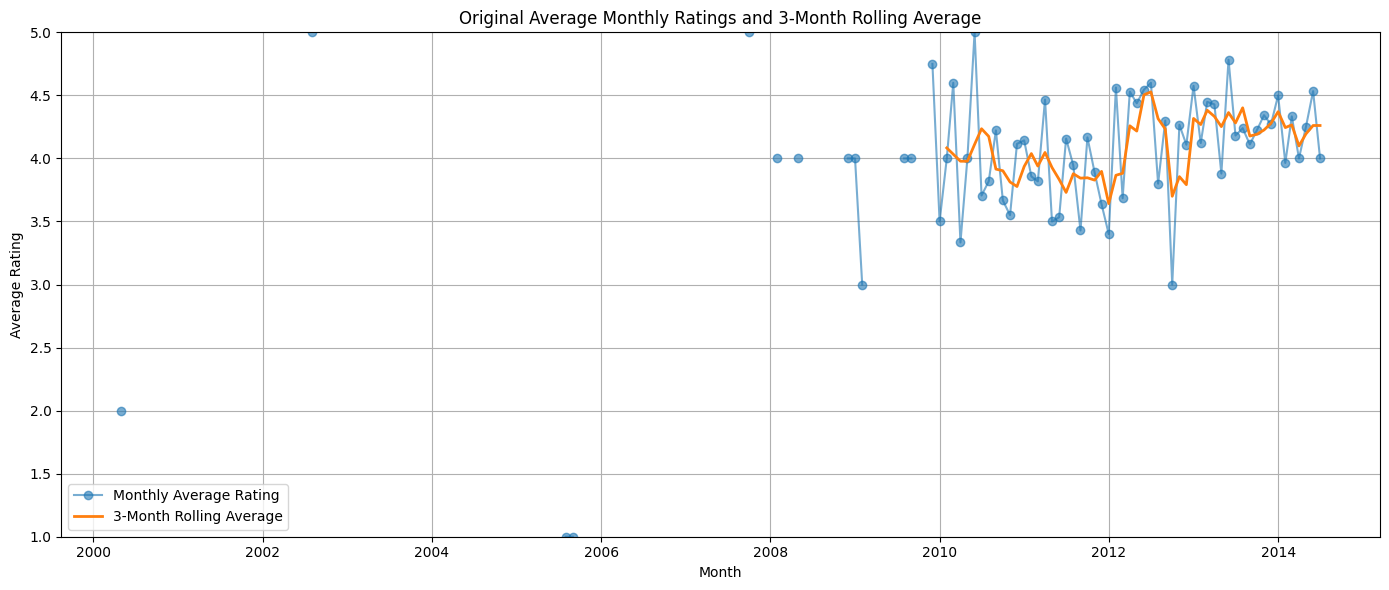

In [40]:
#Comparing the original monthly ratings with the rolling average
plt.figure(figsize=(14, 6))
plt.plot(monthly_avg_rating.index,
    monthly_avg_rating.values,
    label='Monthly Average Rating',
    marker='o',
    alpha=0.6)

plt.plot(rolling_avg_rating.index,
    rolling_avg_rating.values,
    label='3-Month Rolling Average',
    linewidth=2)

plt.title('Original Average Monthly Ratings and 3-Month Rolling Average')
plt.xlabel('Month')
plt.ylabel('Average Rating')
plt.ylim(1, 5)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

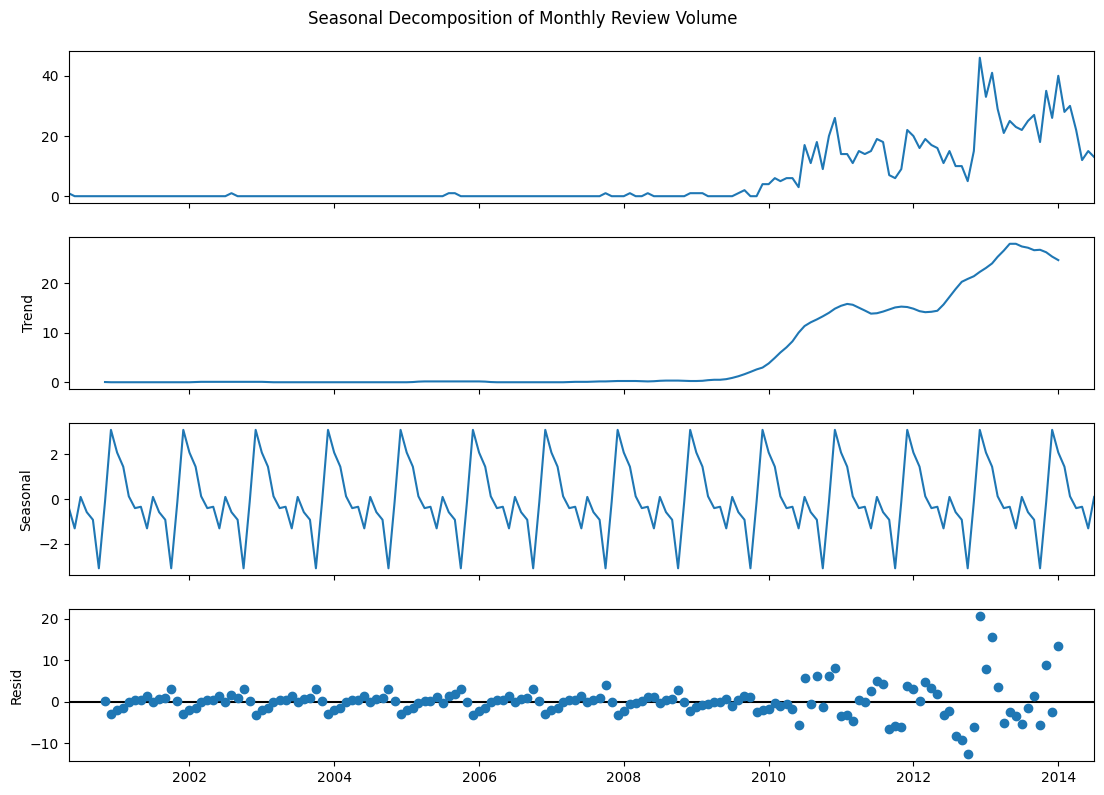

In [68]:
# Decomposition
decomposition = seasonal_decompose(monthly_review_count.fillna(0), model='additive', period=12)
fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.suptitle("Seasonal Decomposition of Monthly Review Volume", y=1.02)
plt.show()

# What overall trends do you notice in review activity and customer ratings over time?

The monthly review count shows that review activity was very low in the early years but started increasing significantly from around 2010. The number of reviews fluctuated over time, with some months recording more reviews than others

The monthly average rating graph shows that ratings varied, but in the later years it was more of four stars and above. This shows that customer feedback was mostly positive during that period, however, some early monthly averages were based on very few reviews, so they may not represent the overall customer experience well

Overall, review activity increased over time, while customer ratings remained generally positive in the later years. Since many months had no reviews, it is difficult to come up with a reliable rating trend for the entire period

The three-month rolling average smooths out fluctuations in the monthly average ratings, making the overall trend easier to observe. The ratings fluctuate around four stars during much of the period shown. The rolling average increases around 2012 to 2013 before remaining stagnant at approximately 4.2–4.4 stars. This suggests that customer ratings were generally positive in the later years

## Part 3: Neural Networks

In this section, you will transform text reviews into numerical features, train a neural network to predict ratings, and evaluate model performance.


In [41]:
# ===================================
# Part 3: Neural Networks Starter Code
# ===================================

# TODO: Import the libraries you need for:
# - data handling
# - train/test splitting
# - text vectorization
# - model building
# - model evaluation

# You will likely need tools from:
# - pandas / numpy
# - sklearn
# - tensorflow / keras

# TODO: Load the dataset.
# df = ...

# TODO: Define:
# X as the review text column
# y as the rating column
# If needed, adjust y so the classes are numbered appropriately for your model.

# TODO: Vectorize the text using TF-IDF.
# Suggested question:
# - How many features do you want to keep?

# vectorizer = ...
# X_tfidf = ...

# TODO: Split the data into training and testing sets.
# Use stratify=y to preserve class balance.

# TODO: One-hot encode the target values if your neural network setup requires it.

# TODO: Build a neural network model.
# Include:
# - an input layer
# - at least one hidden layer
# - an output layer suitable for multi-class classification

# model = ...

# TODO: Compile the model.
# Think about:
# - optimizer
# - loss function
# - evaluation metric(s)

# TODO: Train the model and store the training history.
# history = ...

# TODO: Evaluate the model on the test set.

# TODO: Generate predictions on the test set.

# TODO: Create a classification report and/or confusion matrix to assess performance.

# Reflection prompt:
# Which rating classes does the model predict well, and which ones are harder to classify?


In [42]:
%pip install tensorflow scikit-learn seaborn matplotlib pandas

In [43]:
#importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score,classification_report,confusion_matrix)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [44]:
#loading the dataset
df=pd.read_csv("/content/amazon_reviews_lab.csv")

In [45]:
df_model = df[["review_text", "sentiment_label"]].copy()

df_model = df_model.dropna(subset=["review_text", "sentiment_label"])

df_model["review_text"] = df_model["review_text"].astype(str).str.strip()

df_model = df_model[df_model["review_text"] != ""]

print(df_model.shape)
print("\nSentiment labels:")
print(df_model["sentiment_label"].value_counts())

(997, 2)

Sentiment labels:
sentiment_label
positive    768
negative    135
neutral      94
Name: count, dtype: int64


**Separating X and y**

In [47]:
X = df_model["review_text"]
y = df_model["sentiment_label"]

print(len(X))
print(len(y))
print("unique sentiment labels:", y.unique())

997
997
unique sentiment labels: ['negative' 'positive' 'neutral']


In [49]:
#changing the sentiment labels into numerics
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Label mapping:")
for number, label in enumerate(label_encoder.classes_):
    print(number, "=", label)

Label mapping:
0 = negative
1 = neutral
2 = positive


In [50]:
#train-test split
X_train_text, X_test_text, y_train, y_test = train_test_split(X,y_encoded,test_size=0.2,random_state=42,stratify=y_encoded)

print("Training reviews - ", len(X_train_text))
print("Testing reviews - ", len(X_test_text))

Training reviews -  797
Testing reviews -  200


In [52]:
#Vectorize the text using TF-IDF
tfidf = TfidfVectorizer(max_features=3000,stop_words="english")

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print(X_train.shape)
print(X_test.shape)

(797, 3000)
(200, 3000)


In [53]:
#preparing features for tensorflow
X_train_nn = X_train.toarray().astype("float32")
X_test_nn = X_test.toarray().astype("float32")

print(X_train_nn.shape)
print(X_test_nn.shape)

(797, 3000)
(200, 3000)


**Building a neural network model**

In [54]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(X_train_nn.shape[1],)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(
        len(label_encoder.classes_),
        activation="softmax")])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       384,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 392,579 (1.50 MB)

 Trainable params: 392,579 (1.50 MB)

 Non-trainable params: 0 (0.00 B)

**Compiling the model**

In [55]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

In [59]:
#training the model
history = model.fit(X_train_nn,y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=32,
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,
            restore_best_weights=True)
    ],
    verbose=1)

Epoch 1/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9592 - loss: 0.1527 - val_accuracy: 0.7437 - val_loss: 0.8286
Epoch 2/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9937 - loss: 0.0798 - val_accuracy: 0.7375 - val_loss: 0.9026
Epoch 3/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9984 - loss: 0.0357 - val_accuracy: 0.7250 - val_loss: 1.0432
Epoch 4/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 1.0000 - loss: 0.0161 - val_accuracy: 0.7188 - val_loss: 1.1318
Epoch 5/30
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 1.0000 - loss: 0.0096 - val_accuracy: 0.7063 - val_loss: 1.1892


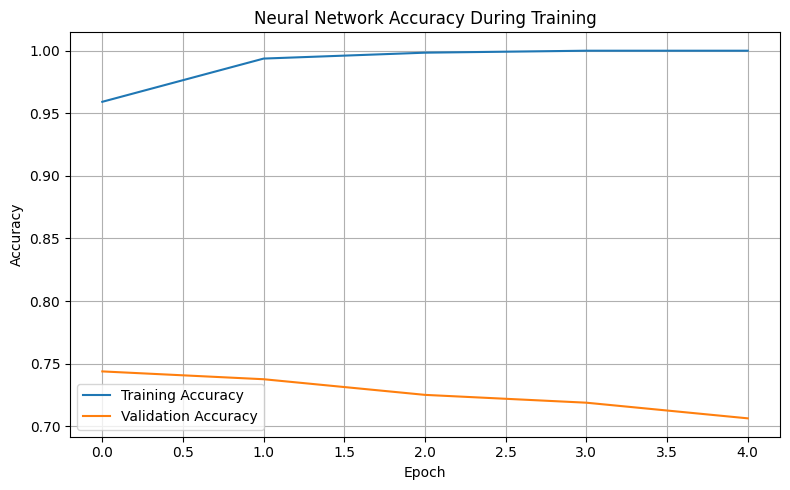

In [60]:
#plotting training accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Neural Network Accuracy During Training")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [61]:
#evaluating on the test set
test_loss, test_accuracy = model.evaluate(
    X_test_nn,
    y_test,
    verbose=0)

print(round(test_loss,4))
print(round(test_accuracy,4))
print(round(test_accuracy * 100,2),"%")

0.7183
0.8
80.0 %


In [62]:
#generating predictions on the test set
y_probabilities = model.predict(X_test_nn)
y_pred = np.argmax(y_probabilities, axis=1)

print("First 10 actual labels")
print(label_encoder.inverse_transform(y_test[:10]))

print("\nFirst 10 predicted labels")
print(label_encoder.inverse_transform(y_pred[:10]))

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
First 10 actual labels
['neutral' 'negative' 'positive' 'positive' 'negative' 'positive'
 'positive' 'positive' 'positive' 'positive']

First 10 predicted labels
['positive' 'positive' 'positive' 'positive' 'positive' 'positive'
 'positive' 'positive' 'positive' 'positive']


In [63]:
#classification report
print(classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0))

              precision    recall  f1-score   support

    negative       0.67      0.37      0.48        27
     neutral       0.00      0.00      0.00        19
    positive       0.81      0.97      0.88       154

    accuracy                           0.80       200
   macro avg       0.49      0.45      0.45       200
weighted avg       0.71      0.80      0.75       200



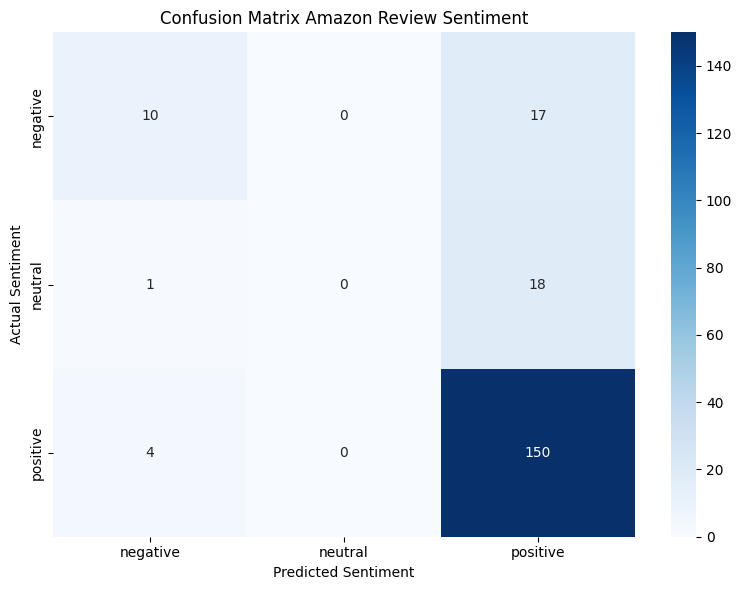

In [65]:
#plotting confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_)))

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_)

plt.title("Confusion Matrix Amazon Review Sentiment")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()
plt.show()

In [67]:
#trying to review one statement
new_review = ["This product is excellent and works really well"]
new_review_features = tfidf.transform(new_review).toarray().astype("float32")

prediction = model.predict(new_review_features, verbose=0)
predicted_class = np.argmax(prediction, axis=1)
predicted_sentiment = label_encoder.inverse_transform(predicted_class)

print(predicted_sentiment[0])
print(prediction[0])

positive
[0.00413198 0.00683665 0.9890314 ]
